# TrendPulse — Part 3: Visualization & Exploratory Data Analysis (EDA)

**Goal:** Explore trending-video records from the US, India, and Great Britain; clean and combine the data; visualize patterns; investigate correlations, view distributions, trending retention, cohorts, and a simple engagement funnel.

> **Dataset note:** The supplied `generate_dataset.py` creates **synthetic practice data**, not official YouTube observations. Findings describe this generated dataset only. Do not present the results as real-world YouTube trends.

## How to run this notebook
1. Keep these files together in a `data/` folder: `USvideos.csv`, `INvideos.csv`, `GBvideos.csv`, and `categories.csv`.
2. Run the cells from top to bottom using **Runtime → Run all** in Google Colab.
3. If running in Colab, upload `trendpulse_part3_data.zip` and extract it into `/content/data/` if the CSVs are not already there.
4. Read the interpretation printed beneath each chart and use the final briefing as a starting point for the README.

**Libraries:** pandas, NumPy, Matplotlib, Plotly. Colab usually includes them already.

## 1. Setup and locate the data files

This cell checks a few common folder locations. If it cannot find the files, it prints a clear message rather than silently continuing.

In [5]:
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from IPython.display import display

COUNTRIES = ["US", "IN", "GB"]
REQUIRED_FILES = ["USvideos.csv", "INvideos.csv", "GBvideos.csv", "categories.csv"]

candidate_dirs = [
    Path("data"),
    Path("/content/data"),
    Path("/content/part3_visualization_eda/data"),
    Path("/content"),
]

DATA_DIR = None
for folder in candidate_dirs:
    if all((folder / name).exists() for name in REQUIRED_FILES):
        DATA_DIR = folder
        break

if DATA_DIR is None:
    zip_candidates = [Path("trendpulse_part3_data.zip"), Path("/content/trendpulse_part3_data.zip")]
    zip_path = next((p for p in zip_candidates if p.exists()), None)
    if zip_path:
        DATA_DIR = Path("/content/data")
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(DATA_DIR)
    else:
        raise FileNotFoundError(
            "Could not find all four CSV files. Put them in a folder named 'data', "
            "or upload trendpulse_part3_data.zip and extract it into /content/data."
        )

print("Data folder:", DATA_DIR.resolve())
for filename in REQUIRED_FILES:
    print(f"{filename}: {'found' if (DATA_DIR / filename).exists() else 'MISSING'}")

Data folder: /content/data
USvideos.csv: found
INvideos.csv: found
GBvideos.csv: found
categories.csv: found


In [6]:
import os
import zipfile
from pathlib import Path

ZIP_PATH = Path("/content/trendpulse_part3_data.zip")
DATA_DIR = Path("/content/data")

# Create the data folder
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Extract the four CSV files
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("ZIP extraction completed!")

# Check the required files
required_files = [
    "USvideos.csv",
    "INvideos.csv",
    "GBvideos.csv",
    "categories.csv"
]

for filename in required_files:
    file_path = DATA_DIR / filename
    print(f"{filename}: {'FOUND' if file_path.exists() else 'MISSING'}")

ZIP extraction completed!
USvideos.csv: FOUND
INvideos.csv: FOUND
GBvideos.csv: FOUND
categories.csv: FOUND


## 2. Load country files and category mapping

We add a `country` column before combining the three country datasets. The category mapping is used to turn category IDs into readable names.

In [7]:
country_frames = []
for country in COUNTRIES:
    file_path = DATA_DIR / f"{country}videos.csv"
    frame = pd.read_csv(file_path)
    frame["country"] = country
    country_frames.append(frame)

raw = pd.concat(country_frames, ignore_index=True)
categories = pd.read_csv(DATA_DIR / "categories.csv")

print("Combined raw shape:", raw.shape)
print("Category mapping shape:", categories.shape)
display(raw.head())
display(categories.head())

Combined raw shape: (46230, 17)
Category mapping shape: (17, 2)


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country
0,g_N-w8LeAi8,17.14.11,Honest Football Prank LEAKED,QuietSpeech10,22,2017-11-14T07:04:28.000Z,Monsoon|Robots,48555,2189.0,180,136.0,https://i.ytimg.com/vi/g_N-w8LeAi8/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
1,Ugyql2NlPAd,17.14.11,Surprising Cricket Review,IncredibleChallenge41,25,2017-11-12T22:35:48.000Z,Winter,198385,1159.0,492,1446.0,https://i.ytimg.com/vi/Ugyql2NlPAd/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
2,8fE19jkxJ9n,17.14.11,Mira Solis - Football (Live) OFFICIAL,WildTutorial42,10,2017-11-13T08:40:22.000Z,Cricket,231656,8742.0,896,432.0,https://i.ytimg.com/vi/8fE19jkxJ9n/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
3,WOY0nn7HCsO,17.14.11,Zed Rivera - Space (Lyric Video)?!,ShockingInterview30,10,2017-10-27T22:21:47.000Z,Festival|Guitar,8083,176.0,8,19.0,https://i.ytimg.com/vi/WOY0nn7HCsO/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
4,2Lc_Cs5VVr_,17.14.11,Surprising Election Recipe,UltimateVlog96,27,2017-11-09T13:20:20.000Z,Festival,373161,11305.0,167,891.0,https://i.ytimg.com/vi/2Lc_Cs5VVr_/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US


,category_id,category_name
0,1,Film & Animation
1,2,Autos & Vehicles
2,10,Music
3,15,Pets & Animals
4,17,Sports


## 3. Initial data profile: shape, dtypes, and missingness

The table below reports every column's dtype and percentage of missing values. We also display only columns that have missing values, as required.

In [8]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_count": raw.isna().sum(),
    "missing_percent": (raw.isna().mean() * 100).round(2)
})
print("Shape (rows, columns):", raw.shape)
display(profile)
missing_columns = profile[profile["missing_count"] > 0]
print("Columns with missing values:")
display(missing_columns if not missing_columns.empty else pd.DataFrame(columns=profile.columns))

Shape (rows, columns): (46230, 17)


,dtype,missing_count,missing_percent
video_id,object,0,0.00
trending_date,object,0,0.00
title,object,0,0.00
channel_title,object,0,0.00
category_id,int64,0,0.00
publish_time,object,0,0.00
tags,object,0,0.00
views,int64,0,0.00
likes,float64,12,0.03
dislikes,int64,0,0.00


Columns with missing values:


,dtype,missing_count,missing_percent
likes,float64,12,0.03
comment_count,float64,36,0.08
description,object,1624,3.51


## 4. Cleaning and preparation

Cleaning choices are deliberately explicit:
- Remove exact duplicate rows.
- Parse date columns when present.
- Convert numeric analysis fields to numeric values.
- Drop rows without a usable `video_id` or `trending_date` because they cannot support unique-video or time-based analysis.
- Keep valid records with missing engagement values; metrics that need those values will ignore missing observations.
- Merge category names while preserving the original category ID.
- Do **not** remove statistical outliers automatically: high views/likes can be legitimate viral observations. We count IQR outliers later and explain the decision.

In [9]:
df = raw.copy()
rows_before = len(df)
duplicate_rows = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

# Parse known date columns only if they exist.
if "trending_date" in df.columns:
    # Synthetic dataset uses YYYY-MM-DD; errors become NaT and are handled below.
    df["trending_date"] = pd.to_datetime(df["trending_date"], errors="coerce")
elif "trending_date" not in df.columns:
    raise KeyError("Expected a 'trending_date' column in the country CSV files.")

if "publish_time" in df.columns:
    df["publish_time"] = pd.to_datetime(df["publish_time"], errors="coerce", utc=True)

numeric_candidates = [
    "views", "likes", "dislikes", "comment_count", "category_id",
    "days_to_trend", "peak_views"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

required_for_time_analysis = [c for c in ["video_id", "trending_date"] if c in df.columns]
before_required_drop = len(df)
df = df.dropna(subset=required_for_time_analysis).copy()
removed_required = before_required_drop - len(df)

# Normalise category mapping column names where possible.
cat_cols = {c.lower(): c for c in categories.columns}
id_col = cat_cols.get("category_id")
name_col = cat_cols.get("category_name") or cat_cols.get("title") or cat_cols.get("name")

if id_col and name_col:
    category_lookup = categories[[id_col, name_col]].copy()
    category_lookup.columns = ["category_id", "category_name"]
    category_lookup["category_id"] = pd.to_numeric(category_lookup["category_id"], errors="coerce")
    df["category_id"] = pd.to_numeric(df["category_id"], errors="coerce")
    df = df.merge(category_lookup.drop_duplicates("category_id"), on="category_id", how="left")
else:
    print("Warning: category mapping columns were not recognised; using category_id as fallback.")
    df["category_name"] = df["category_id"].astype("Int64").astype(str)

df["category_name"] = df["category_name"].fillna("Unknown")
df["trending_day"] = df.groupby(["country", "video_id"])["trending_date"].rank(method="dense").astype(int)

print(f"Rows before cleaning: {rows_before:,}")
print(f"Exact duplicate rows removed: {duplicate_rows:,}")
print(f"Rows removed for missing video_id/trending_date: {removed_required:,}")
print(f"Rows after cleaning: {len(df):,}")
print(f"Rows removed in total: {rows_before - len(df):,}")
print("Final shape:", df.shape)
display(df.head())

/tmp/ipykernel_1005/666596979.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["trending_date"] = pd.to_datetime(df["trending_date"], errors="coerce")


Rows before cleaning: 46,230
Exact duplicate rows removed: 230
Rows removed for missing video_id/trending_date: 31,400
Rows after cleaning: 14,600
Rows removed in total: 31,630
Final shape: (14600, 19)


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country,category_name,trending_day
0,fYqCEYwaysU,2012-01-17,Perfect Cars Unboxing,CrazyTrailer91,24,2017-11-07 22:30:05+00:00,Space,1136172,27785.0,1936,3563.0,https://i.ytimg.com/vi/fYqCEYwaysU/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,Entertainment,1
1,BsTMdCTYs7P,2012-01-17,Surprising Guitar Update,Brand NewUnboxing21,24,2017-11-11 12:46:59+00:00,Cars|Phones|Space,13475807,677884.0,57145,78024.0,https://i.ytimg.com/vi/BsTMdCTYs7P/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,Entertainment,1
2,wOOstfs0P87,2012-01-17,Final Cricket Trailer LIVE,OfficialSecret61,24,2017-11-11 04:32:06+00:00,Festival|Budget|Robots|Guitar,5008993,170931.0,5107,24445.0,https://i.ytimg.com/vi/wOOstfs0P87/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,Entertainment,1
3,KDAc90So7lp,2012-01-17,Ultimate Bangalore Trailer,CrazyTrailer91,24,2017-11-18 11:01:15+00:00,Pasta|Budget|Chess,4771912,152859.0,12196,23331.0,https://i.ytimg.com/vi/KDAc90So7lp/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,Entertainment,1
4,EZxtZEUUURZ,2012-01-17,Rook & Vale - Bangalore (Lyric Video) FULL,EpicBreakdown59,10,2017-11-20 03:34:15+00:00,Budget|Space|Cats,359935,38370.0,1699,907.0,https://i.ytimg.com/vi/EZxtZEUUURZ/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,Music,1


## 5. Prepare a one-row-per-video table

A video may appear on multiple trending days. For video-level questions, we aggregate records into one row per country/video, using maximum views as peak views and counting how many distinct trending days it appeared.

In [10]:
# Use a stable video key within country because country exports can contain overlapping IDs.
video_group_cols = ["country", "video_id"]
agg_spec = {
    "views": "max",
    "likes": "max",
    "dislikes": "max",
    "comment_count": "max",
    "category_id": "first",
    "category_name": "first",
    "trending_date": ["min", "max", "nunique"],
}
# Optional generated feature, if present.
if "days_to_trend" in df.columns:
    agg_spec["days_to_trend"] = "first"

videos = df.groupby(video_group_cols, dropna=False).agg(agg_spec)
videos.columns = [
    "_".join(str(part) for part in col if part != "") if isinstance(col, tuple) else str(col)
    for col in videos.columns
]
videos = videos.reset_index().rename(columns={
    "views_max": "peak_views",
    "likes_max": "peak_likes",
    "dislikes_max": "peak_dislikes",
    "comment_count_max": "peak_comment_count",
    "trending_date_min": "first_trending_date",
    "trending_date_max": "last_trending_date",
    "trending_date_nunique": "trending_days",
})
# Some pandas versions can name single-level columns differently; validate essential fields.
print("Unique country/video records:", len(videos))
display(videos.head())

Unique country/video records: 5575


,country,video_id,peak_views,peak_likes,peak_dislikes,peak_comment_count,category_id_first,category_name_first,first_trending_date,last_trending_date,trending_days
0,GB,--pb5oKkYrH,582515,12694.0,577,767.0,10,Music,2012-04-17,2012-07-17,4
1,GB,-3WfJZgVB5h,1350732,59351.0,1750,2277.0,10,Music,2001-01-18,2001-02-18,2
2,GB,-48JdRO2P5_,347038,6007.0,252,1853.0,26,Howto & Style,2012-06-17,2012-07-17,2
3,GB,-5gYZ79gyl-,87771,3702.0,139,162.0,26,Howto & Style,2001-07-18,2001-07-18,1
4,GB,-5iZ5HWgnCs,28154,1323.0,15,86.0,15,Pets & Animals,2012-01-17,2012-01-17,1


## 6. Matplotlib chart 1 — number of trending records by category

A bar chart is suitable because categories are discrete groups and the goal is to compare counts.

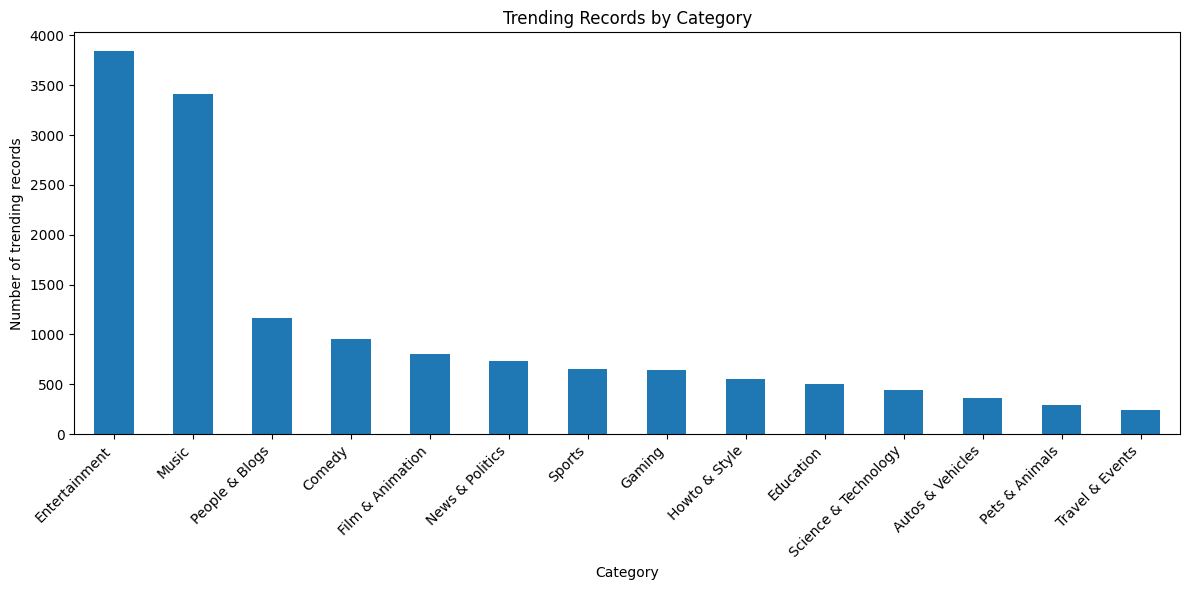

Interpretation: Entertainment has the most trending records (3,839) in this dataset. Record counts reflect repeated daily appearances, not unique videos. A bar chart fits because category is categorical and counts are numeric.


In [11]:
category_counts = df["category_name"].value_counts().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
category_counts.plot(kind="bar")
plt.title("Trending Records by Category")
plt.xlabel("Category")
plt.ylabel("Number of trending records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

top_category = category_counts.index[0] if len(category_counts) else "N/A"
top_count = int(category_counts.iloc[0]) if len(category_counts) else 0
print(
    f"Interpretation: {top_category} has the most trending records ({top_count:,}) in this dataset. "
    "Record counts reflect repeated daily appearances, not unique videos. "
    "A bar chart fits because category is categorical and counts are numeric."
)

## 7. Matplotlib chart 2 — distribution of views (log scale)

Video views are often highly skewed, so a log-scaled histogram helps show both lower and very high view counts. Zero or negative values are excluded from this log plot only.

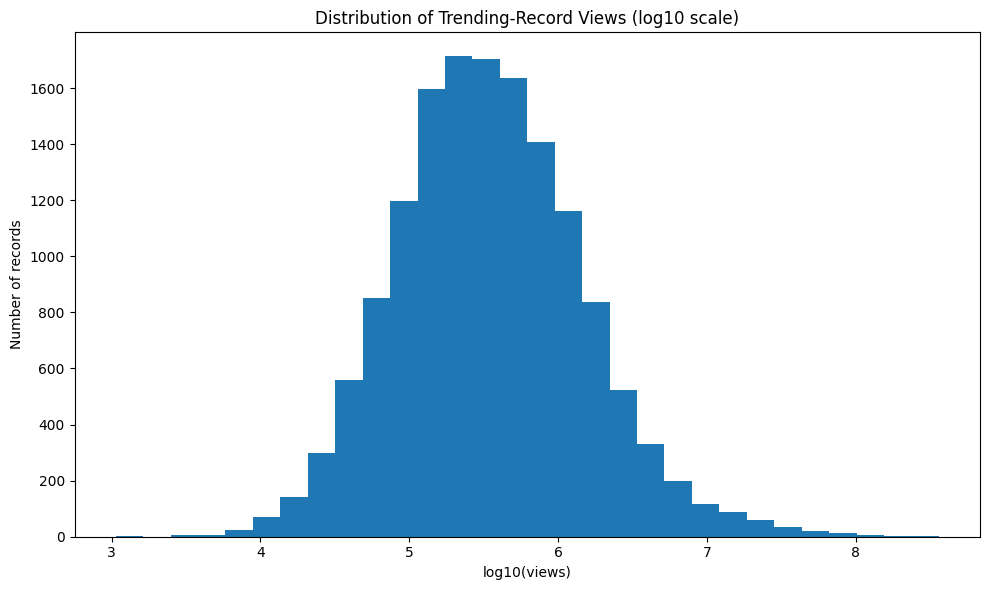

Interpretation: The chart uses 14,600 positive-view records. A long tail toward larger log10(view) values indicates that a smaller number of records have much higher views. A histogram fits because views are numeric and the goal is to inspect their distribution.


In [12]:
views_positive = df.loc[df["views"] > 0, "views"].dropna()
plt.figure(figsize=(10, 6))
plt.hist(np.log10(views_positive), bins=30)
plt.title("Distribution of Trending-Record Views (log10 scale)")
plt.xlabel("log10(views)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

print(
    f"Interpretation: The chart uses {len(views_positive):,} positive-view records. "
    "A long tail toward larger log10(view) values indicates that a smaller number of records have much higher views. "
    "A histogram fits because views are numeric and the goal is to inspect their distribution."
)

## 8. Matplotlib chart 3 — views versus likes

A scatter plot helps inspect whether records with more views tend to have more likes. The axes use log scales to make the spread easier to inspect.

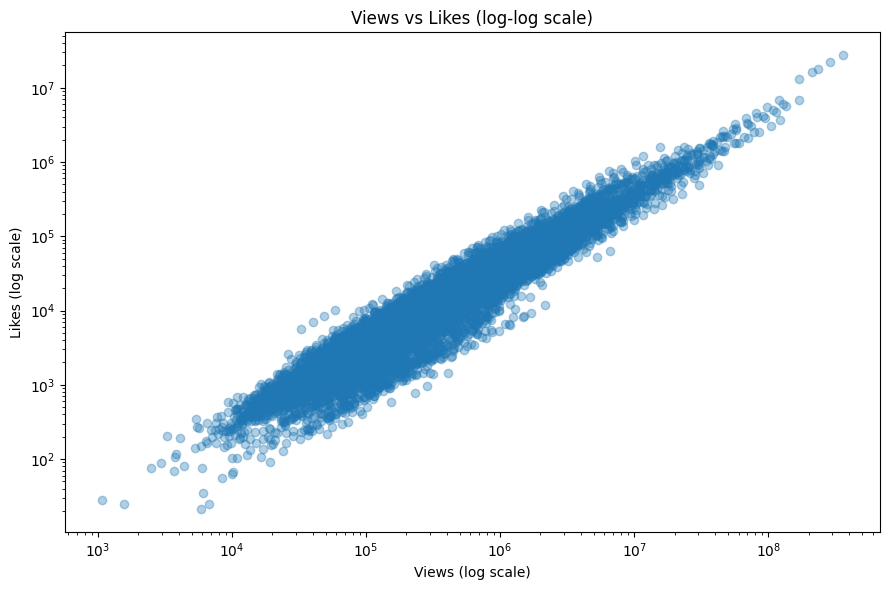

Interpretation: The Pearson correlation for positive views and likes is 0.950. An upward pattern would mean higher-view records generally also have more likes, but this does not establish causation. A scatter plot fits because it compares two numeric variables record by record.


In [13]:
scatter_data = df[(df["views"] > 0) & (df["likes"] > 0)].dropna(subset=["views", "likes"])
plt.figure(figsize=(9, 6))
plt.scatter(scatter_data["views"], scatter_data["likes"], alpha=0.35)
plt.xscale("log")
plt.yscale("log")
plt.title("Views vs Likes (log-log scale)")
plt.xlabel("Views (log scale)")
plt.ylabel("Likes (log scale)")
plt.tight_layout()
plt.show()

corr_vl = scatter_data[["views", "likes"]].corr().iloc[0, 1] if len(scatter_data) > 1 else np.nan
print(
    f"Interpretation: The Pearson correlation for positive views and likes is {corr_vl:.3f}. "
    "An upward pattern would mean higher-view records generally also have more likes, but this does not establish causation. "
    "A scatter plot fits because it compares two numeric variables record by record."
)

## 9. Matplotlib chart 4 — daily trending-record volume

This line chart shows how many records occur on each trending date. A line chart fits ordered time data because it reveals changes over time.

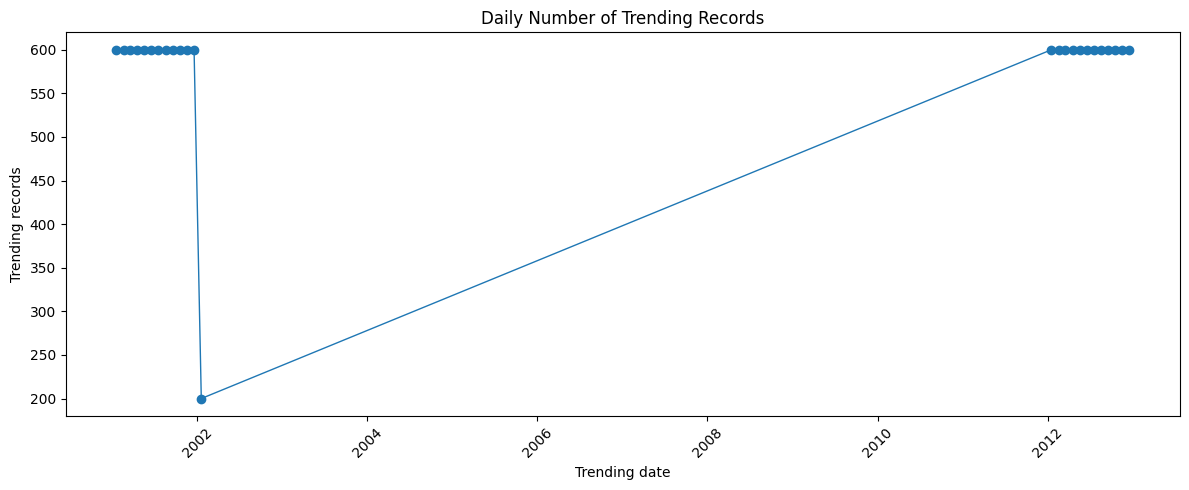

Interpretation: The dataset spans 25 distinct trending dates. The daily record count ranges from 200 to 600. A line chart fits because dates have a natural chronological order.


In [14]:
daily_records = df.groupby(df["trending_date"].dt.date).size().sort_index()
plt.figure(figsize=(12, 5))
plt.plot(pd.to_datetime(daily_records.index), daily_records.values, marker="o", linewidth=1)
plt.title("Daily Number of Trending Records")
plt.xlabel("Trending date")
plt.ylabel("Trending records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(
    f"Interpretation: The dataset spans {len(daily_records):,} distinct trending dates. "
    f"The daily record count ranges from {int(daily_records.min()):,} to {int(daily_records.max()):,}. "
    "A line chart fits because dates have a natural chronological order."
)

## 10. Matplotlib chart 5 — peak views by category

A boxplot compares the median and spread of peak views by category. The log scale makes very different view magnitudes easier to compare.

In [17]:

# Fix category column names in the videos DataFrame

videos = videos.rename(columns={
    "category_name_first": "category_name",
    "category_id_first": "category_id"
})

print("Category column fixed!")
print([
    col for col in videos.columns
    if "category" in col
])


Category column fixed!
['category_id', 'category_name']


Available columns: ['country', 'video_id', 'peak_views', 'peak_likes', 'peak_dislikes', 'peak_comment_count', 'category_id', 'category_name', 'first_trending_date', 'last_trending_date', 'trending_days']


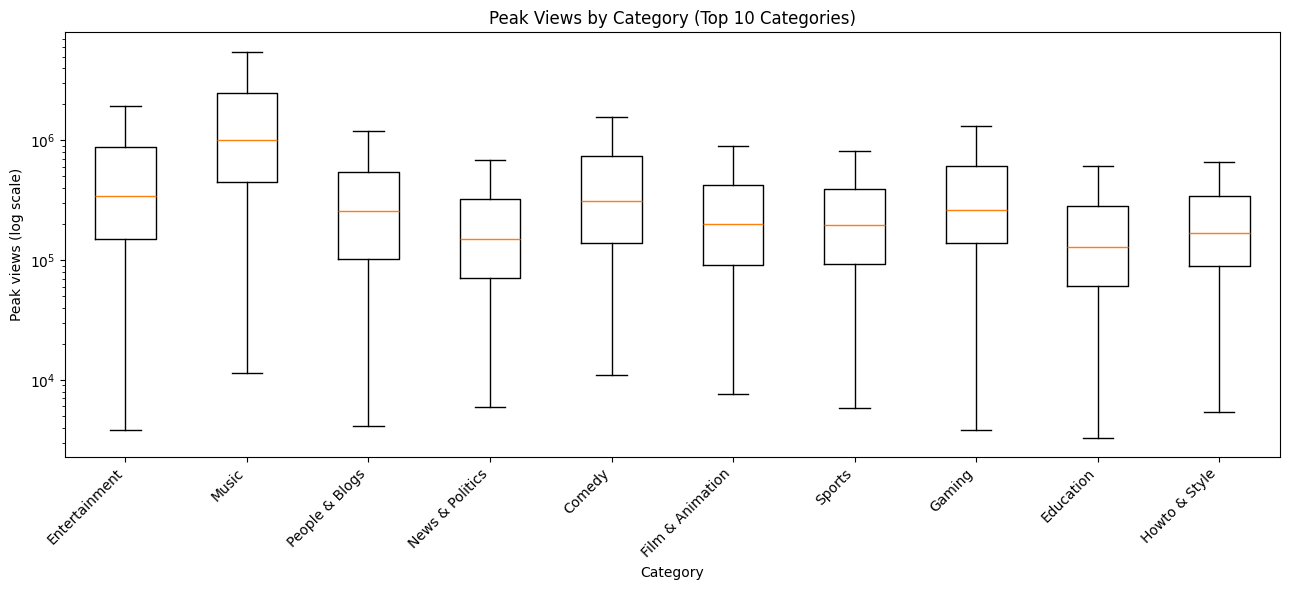

Highest median peak views: Music (1,010,765)
Interpretation: The boxplot compares median peak views and the spread of views across categories. A log scale helps compare categories with very different view counts. A boxplot fits because it summarizes a numeric distribution for each category.


In [18]:

# Matplotlib chart 5 — Peak views by category

# Check that the required columns exist
print("Available columns:", videos.columns.tolist())

# Keep valid peak views and category names
box_data = videos.dropna(
    subset=["category_name", "peak_views"]
).copy()

box_data = box_data[box_data["peak_views"] > 0]

# Select the 10 categories with the most unique videos
top_categories = (
    box_data["category_name"]
    .value_counts()
    .head(10)
    .index
    .tolist()
)

box_data = box_data[
    box_data["category_name"].isin(top_categories)
]

# Prepare one list of values per category
box_values = [
    box_data.loc[
        box_data["category_name"] == category,
        "peak_views"
    ].to_numpy()
    for category in top_categories
]

# Remove any empty groups
valid_groups = [
    (category, values)
    for category, values in zip(top_categories, box_values)
    if len(values) > 0
]

if valid_groups:
    labels, values = zip(*valid_groups)

    plt.figure(figsize=(13, 6))
    plt.boxplot(values, tick_labels=list(labels), showfliers=False)
    plt.yscale("log")
    plt.title("Peak Views by Category (Top 10 Categories)")
    plt.xlabel("Category")
    plt.ylabel("Peak views (log scale)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    medians = (
        box_data.groupby("category_name")["peak_views"]
        .median()
        .sort_values(ascending=False)
    )

    print(
        f"Highest median peak views: {medians.index[0]} "
        f"({medians.iloc[0]:,.0f})"
    )
    print(
        "Interpretation: The boxplot compares median peak views "
        "and the spread of views across categories. A log scale "
        "helps compare categories with very different view counts. "
        "A boxplot fits because it summarizes a numeric distribution "
        "for each category."
    )
else:
    print("No valid category and peak-view data available.")


## 11. Plotly interactive chart 1 — views versus likes by category

Hover over points to inspect the title and values. This interactive scatter plot compares two numeric variables and uses color to show a category grouping.

In [19]:
hover_cols = [c for c in ["title", "country", "category_name", "views", "likes", "video_id"] if c in df.columns]
interactive_scatter = df[(df["views"] > 0) & (df["likes"] >= 0)].dropna(subset=["views", "likes"]).copy()
# Limit displayed points for browser responsiveness; data analysis above still uses the full data.
if len(interactive_scatter) > 5000:
    interactive_scatter = interactive_scatter.sample(5000, random_state=42)

fig = px.scatter(
    interactive_scatter,
    x="views",
    y="likes",
    color="category_name",
    hover_data=hover_cols,
    log_x=True,
    log_y=True,
    title="Interactive Views vs Likes by Category",
    labels={"views": "Views (log scale)", "likes": "Likes (log scale)", "category_name": "Category"}
)
fig.show()
print(
    "Interpretation: Use hover to inspect individual records and compare category clusters. "
    "Categories occupying the upper-right area contain records with both high views and high likes. "
    "An interactive scatter plot is suitable because it supports detailed inspection of many numeric points."
)

Interpretation: Use hover to inspect individual records and compare category clusters. Categories occupying the upper-right area contain records with both high views and high likes. An interactive scatter plot is suitable because it supports detailed inspection of many numeric points.


## 12. Plotly interactive chart 2 — average peak views by category and country

This grouped bar chart compares average peak views across countries for each category. Hover for exact values.

In [20]:
avg_views = (
    videos.dropna(subset=["peak_views"])
    .groupby(["category_name", "country"], as_index=False)["peak_views"]
    .mean()
    .rename(columns={"peak_views": "average_peak_views"})
)
# Display the 12 categories with the highest overall average to keep the chart legible.
selected_cats = (
    avg_views.groupby("category_name")["average_peak_views"].mean()
    .sort_values(ascending=False).head(12).index
)
avg_views_plot = avg_views[avg_views["category_name"].isin(selected_cats)]

fig = px.bar(
    avg_views_plot,
    x="category_name",
    y="average_peak_views",
    color="country",
    barmode="group",
    title="Average Peak Views by Category and Country (Top 12 Categories)",
    labels={
        "category_name": "Category",
        "average_peak_views": "Average peak views",
        "country": "Country"
    },
    hover_data={"average_peak_views": ":,.0f"}
)
fig.update_layout(xaxis_tickangle=-40)
fig.show()

print(
    "Interpretation: Compare the grouped bars within each category to see which country has the larger average peak views. "
    "Averages can be affected by unusually popular videos, so they should be read alongside medians and sample sizes. "
    "A grouped interactive bar chart fits categorical comparisons with a numeric summary."
)

Interpretation: Compare the grouped bars within each category to see which country has the larger average peak views. Averages can be affected by unusually popular videos, so they should be read alongside medians and sample sizes. A grouped interactive bar chart fits categorical comparisons with a numeric summary.


## 13. Views and likes: mean, median, mode, skewness, and IQR outliers

We calculate mean, median, and mode for peak views and peak likes at the unique-video level. Skewness is assessed using the mean/median/mode ordering as a simple heuristic; the ordering can be imperfect for multimodal or irregular distributions.

In [21]:
def distribution_summary(series):
    s = pd.to_numeric(series, errors="coerce").dropna()
    if s.empty:
        return {"count": 0, "mean": np.nan, "median": np.nan, "mode": np.nan,
                "skewness": np.nan, "skew_conclusion": "Not enough data",
                "q1": np.nan, "q3": np.nan, "iqr": np.nan,
                "lower_bound": np.nan, "upper_bound": np.nan, "outlier_count": 0}
    modes = s.mode()
    mode_value = modes.iloc[0] if not modes.empty else np.nan
    mean_value, median_value = s.mean(), s.median()
    if mean_value > median_value > mode_value:
        conclusion = "Likely right-skewed (mean > median > mode)"
    elif mean_value < median_value < mode_value:
        conclusion = "Likely left-skewed (mean < median < mode)"
    elif np.isclose(mean_value, median_value, equal_nan=False) and np.isclose(median_value, mode_value, equal_nan=False):
        conclusion = "Approximately symmetric by mean/median/mode ordering"
    else:
        conclusion = "No clear skew conclusion from mean/median/mode ordering"
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_count = int(((s < lower) | (s > upper)).sum())
    return {
        "count": int(s.size), "mean": mean_value, "median": median_value,
        "mode": mode_value, "skewness": s.skew(), "skew_conclusion": conclusion,
        "q1": q1, "q3": q3, "iqr": iqr, "lower_bound": lower,
        "upper_bound": upper, "outlier_count": outlier_count
    }

view_summary = distribution_summary(videos["peak_views"])
like_summary = distribution_summary(videos["peak_likes"])
summary_table = pd.DataFrame([view_summary, like_summary], index=["Peak views", "Peak likes"])
display(summary_table)

,count,mean,median,mode,skewness,skew_conclusion,q1,q3,iqr,lower_bound,upper_bound,outlier_count
Peak views,5575,1.105866e+06,275165.0,19717.0,32.686311,Likely right-skewed (mean > median > mode),118551.5,720796.5,602245.0,-784816.00,1624164.00,615
Peak likes,5575,4.437308e+04,8591.0,0.0,51.580925,Likely right-skewed (mean > median > mode),3098.5,24951.0,21852.5,-29680.25,57729.75,628


### IQR outlier decision

The IQR rule labels values below `Q1 − 1.5 × IQR` or above `Q3 + 1.5 × IQR` as statistical outliers. **Decision: keep these observations for the main analysis** unless data validation proves they are errors. In a trending-video dataset, extreme views and likes may represent genuine viral videos; deleting them would bias the analysis toward ordinary videos. We use a log scale or robust summaries when needed.

## 14. Correlation matrix and heatmap

We compute pairwise correlations across available numeric columns, including views, likes, dislikes, comments, and days-to-trend when present. Correlation measures association, not cause and effect.

,views,likes,dislikes,comment_count
views,1.000000,0.949308,0.937030,0.905033
likes,0.949308,1.000000,0.889412,0.825145
dislikes,0.937030,0.889412,1.000000,0.905451
comment_count,0.905033,0.825145,0.905451,1.000000


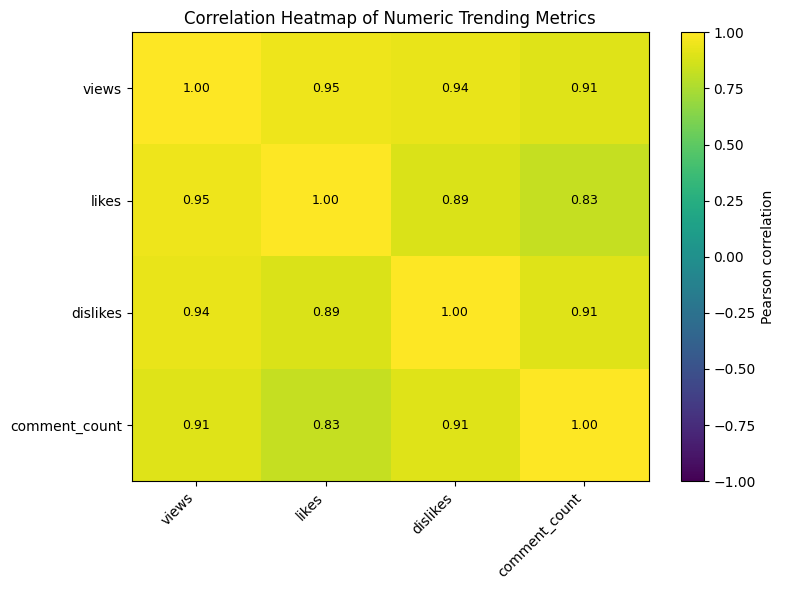

Two strongest absolute off-diagonal correlations:
- views vs likes: r = 0.949 (absolute r = 0.949)
- views vs dislikes: r = 0.937 (absolute r = 0.937)
Interpretation: The strongest pairs above show the largest linear associations among the selected numeric metrics. Correlation does not prove causation; both metrics may be influenced by other factors such as category, audience size, or time trending.


In [22]:
correlation_columns = [
    c for c in ["views", "likes", "dislikes", "comment_count", "days_to_trend"]
    if c in df.columns and pd.api.types.is_numeric_dtype(df[c])
]
corr_data = df[correlation_columns].dropna(how="all")
corr_matrix = corr_data.corr(numeric_only=True)
display(corr_matrix)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr_matrix, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr_matrix.index)), corr_matrix.index)
ax.set_title("Correlation Heatmap of Numeric Trending Metrics")
for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):
        val = corr_matrix.iloc[i, j]
        if pd.notna(val):
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

pairs = []
for i, col_a in enumerate(corr_matrix.columns):
    for col_b in corr_matrix.columns[i+1:]:
        value = corr_matrix.loc[col_a, col_b]
        if pd.notna(value):
            pairs.append((col_a, col_b, float(value), abs(float(value))))
pairs = sorted(pairs, key=lambda x: x[3], reverse=True)
print("Two strongest absolute off-diagonal correlations:")
for col_a, col_b, value, abs_value in pairs[:2]:
    print(f"- {col_a} vs {col_b}: r = {value:.3f} (absolute r = {abs_value:.3f})")
print(
    "Interpretation: The strongest pairs above show the largest linear associations among the selected numeric metrics. "
    "Correlation does not prove causation; both metrics may be influenced by other factors such as category, audience size, or time trending."
)

## 15. Engagement funnel using unique videos

Funnel stages:
1. All unique videos that trended.
2. Videos with peak views above the dataset median.
3. Videos with peak views above the 90th percentile.
4. Videos with at least 1,000 peak comments.

Conversion rate is each stage's count divided by the previous stage's count. The largest drop-off is calculated between adjacent stages. The 1,000-comment threshold is a chosen business rule for this exercise, not an industry standard.

In [23]:
funnel_videos = videos.dropna(subset=["peak_views"]).copy()
total_videos = len(funnel_videos)
median_peak_views = funnel_videos["peak_views"].median() if total_videos else np.nan
p90_peak_views = funnel_videos["peak_views"].quantile(0.90) if total_videos else np.nan

stage_masks = [
    pd.Series(True, index=funnel_videos.index),
    funnel_videos["peak_views"] > median_peak_views if total_videos else pd.Series(False, index=funnel_videos.index),
    funnel_videos["peak_views"] > p90_peak_views if total_videos else pd.Series(False, index=funnel_videos.index),
    (funnel_videos["peak_comment_count"] >= 1000) if "peak_comment_count" in funnel_videos.columns else pd.Series(False, index=funnel_videos.index),
]
stage_names = [
    "All videos that trended",
    "Peak views above median",
    "Peak views above 90th percentile",
    "1,000+ peak comments"
]
stage_counts = [int(mask.sum()) for mask in stage_masks]
conversion = [np.nan] + [
    (stage_counts[i] / stage_counts[i-1] * 100) if stage_counts[i-1] else np.nan
    for i in range(1, len(stage_counts))
]
funnel_table = pd.DataFrame({
    "stage": stage_names,
    "video_count": stage_counts,
    "conversion_from_previous_percent": [np.nan] + [round(x, 2) if pd.notna(x) else np.nan for x in conversion[1:]]
})
display(funnel_table)

dropoffs = [stage_counts[i-1] - stage_counts[i] for i in range(1, len(stage_counts))]
if dropoffs:
    largest_idx = int(np.argmax(dropoffs)) + 1
    print(
        f"Largest absolute drop-off: {stage_names[largest_idx-1]} → {stage_names[largest_idx]} "
        f"({dropoffs[largest_idx-1]:,} videos)."
    )
print(
    "Interpretation: The funnel narrows as increasingly strict view and comment conditions are applied. "
    "The largest absolute drop-off identifies the stage where the most videos are filtered out; the thresholds are analytical choices for this assignment."
)

,stage,video_count,conversion_from_previous_percent
0,All videos that trended,5575,NaN
1,Peak views above median,2787,49.99
2,Peak views above 90th percentile,558,20.02
3,"1,000+ peak comments",2746,492.11


Largest absolute drop-off: All videos that trended → Peak views above median (2,788 videos).
Interpretation: The funnel narrows as increasingly strict view and comment conditions are applied. The largest absolute drop-off identifies the stage where the most videos are filtered out; the thresholds are analytical choices for this assignment.


## 16. Trending retention / lifespan

A video's first trending date is day 1. For each country/video, we count distinct trending dates and calculate the percentage appearing on at least days 2, 3, 5, and 7. We also compare retention curves by country and category. This uses observed trending records; it does not assume a video stopped trending permanently after its last observed day.

Unique country/video units in retention analysis: 5,575


,day,videos_still_trending,percent_of_videos
0,2,3293,59.07
1,3,2071,37.15
2,5,835,14.98
3,7,349,6.26


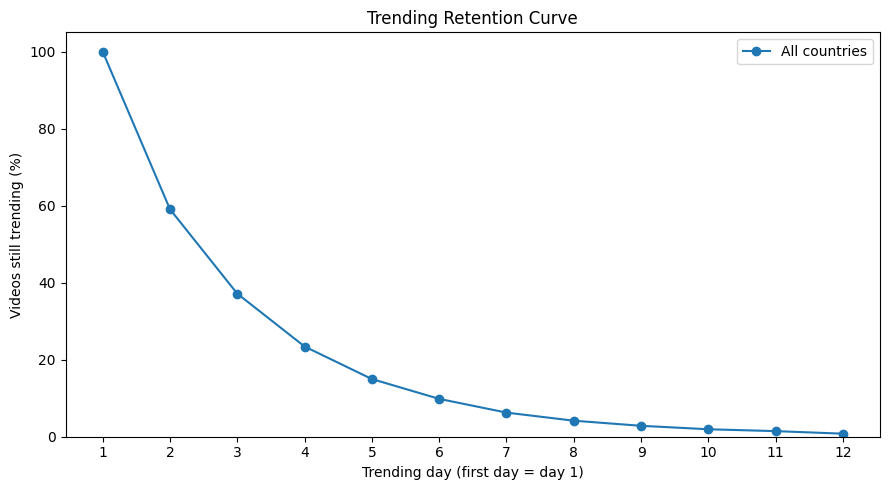

Interpretation: Retention percentage should generally decline as the day number increases. A steeper decline means many videos disappear from the trending list quickly, while a flatter curve means longer observed trending lifespans. A line chart fits because retention is measured across ordered days.


In [24]:
# Use the observed rank of each trending record to identify day number.
retention_records = df[["country", "video_id", "category_name", "trending_date", "trending_day"]].drop_duplicates()
video_first = retention_records.groupby(["country", "video_id"], as_index=False).agg(
    category_name=("category_name", "first"),
    first_trending_date=("trending_date", "min"),
    lifespan_days=("trending_day", "max")
)
n_retention_videos = len(video_first)
target_days = [2, 3, 5, 7]
retention_summary = pd.DataFrame({
    "day": target_days,
    "videos_still_trending": [
        int((video_first["lifespan_days"] >= day).sum()) for day in target_days
    ],
})
retention_summary["percent_of_videos"] = (
    retention_summary["videos_still_trending"] / n_retention_videos * 100
    if n_retention_videos else np.nan
).round(2)
print(f"Unique country/video units in retention analysis: {n_retention_videos:,}")
display(retention_summary)

# Overall curve through day 14.
max_day = min(14, int(video_first["lifespan_days"].max())) if n_retention_videos else 1
days = np.arange(1, max_day + 1)
overall_retention = [(video_first["lifespan_days"] >= day).mean() * 100 for day in days] if n_retention_videos else []
plt.figure(figsize=(9, 5))
plt.plot(days, overall_retention, marker="o", label="All countries")
plt.title("Trending Retention Curve")
plt.xlabel("Trending day (first day = day 1)")
plt.ylabel("Videos still trending (%)")
plt.xticks(days)
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Interpretation: Retention percentage should generally decline as the day number increases. "
    "A steeper decline means many videos disappear from the trending list quickly, while a flatter curve means longer observed trending lifespans. "
    "A line chart fits because retention is measured across ordered days."
)

### Compare retention across countries and categories

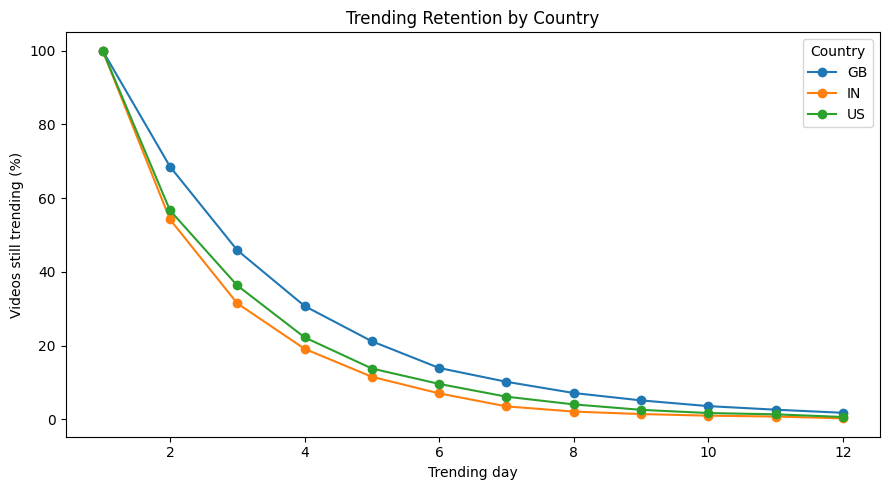

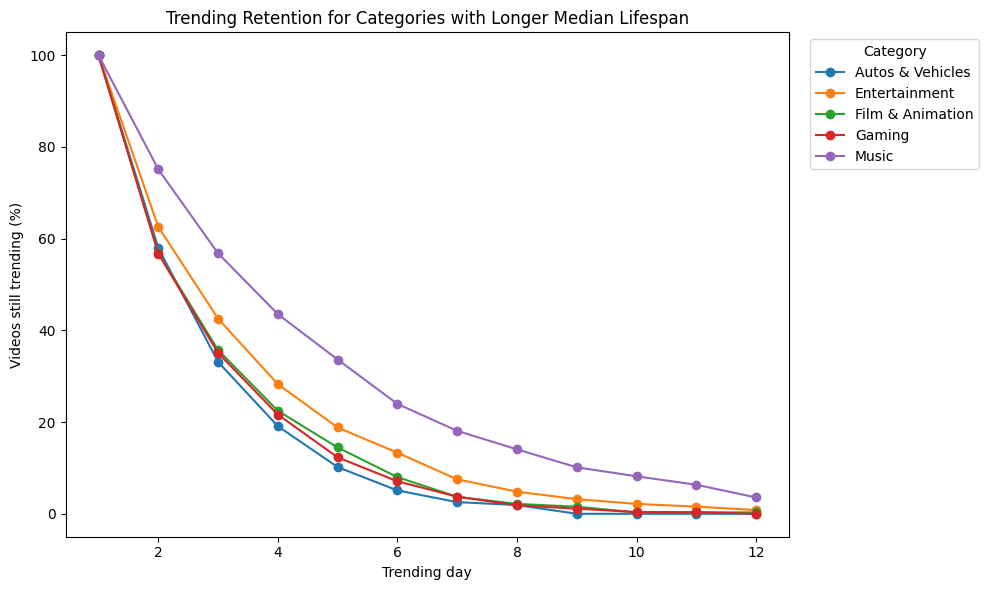

Country day-7 retention (%):


,day_7_retention_percent
country,
GB,10.16
US,6.12
IN,3.48


Category median observed lifespan (top categories):


,median_lifespan_days
category_name,
Music,3.0
Autos & Vehicles,2.0
Entertainment,2.0
Film & Animation,2.0
Gaming,2.0


Interpretation: The higher country day-7 percentage indicates a larger share of that country's observed videos remained trending for at least seven distinct trending days. Category retention curves show which categories tend to persist versus vanish sooner. Small groups and the fixed observation window can make these comparisons unstable.


In [25]:
def retention_by_group(group_col, min_videos=10):
    counts = video_first[group_col].value_counts()
    keep_groups = counts[counts >= min_videos].index
    subset = video_first[video_first[group_col].isin(keep_groups)]
    max_day_local = min(14, int(subset["lifespan_days"].max())) if not subset.empty else 1
    result = []
    for group_value, group_df in subset.groupby(group_col):
        for day in range(1, max_day_local + 1):
            result.append({
                group_col: group_value,
                "day": day,
                "retention_percent": (group_df["lifespan_days"] >= day).mean() * 100,
                "video_count": len(group_df)
            })
    return pd.DataFrame(result)

country_retention = retention_by_group("country", min_videos=1)
plt.figure(figsize=(9, 5))
for country, part in country_retention.groupby("country"):
    plt.plot(part["day"], part["retention_percent"], marker="o", label=country)
plt.title("Trending Retention by Country")
plt.xlabel("Trending day")
plt.ylabel("Videos still trending (%)")
plt.legend(title="Country")
plt.tight_layout()
plt.show()

category_retention = retention_by_group("category_name", min_videos=10)
# Select categories with the highest median observed lifespan for a readable comparison.
category_lifespans = video_first.groupby("category_name")["lifespan_days"].median().sort_values(ascending=False)
chosen_categories = category_lifespans.head(5).index
cat_retention_plot = category_retention[category_retention["category_name"].isin(chosen_categories)]
plt.figure(figsize=(10, 6))
for category, part in cat_retention_plot.groupby("category_name"):
    plt.plot(part["day"], part["retention_percent"], marker="o", label=category)
plt.title("Trending Retention for Categories with Longer Median Lifespan")
plt.xlabel("Trending day")
plt.ylabel("Videos still trending (%)")
plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

country_day7 = video_first.groupby("country").apply(
    lambda g: (g["lifespan_days"] >= 7).mean() * 100, include_groups=False
).sort_values(ascending=False)
print("Country day-7 retention (%):")
display(country_day7.rename("day_7_retention_percent").to_frame().round(2))
print("Category median observed lifespan (top categories):")
display(category_lifespans.head(5).rename("median_lifespan_days").to_frame())
print(
    "Interpretation: The higher country day-7 percentage indicates a larger share of that country's observed videos remained trending for at least seven distinct trending days. "
    "Category retention curves show which categories tend to persist versus vanish sooner. "
    "Small groups and the fixed observation window can make these comparisons unstable."
)

## 17. Cohort analysis by week/month of first trending

We group unique videos by the week they first appeared as trending, then compare average peak views and average observed lifespan. The cohort date is based on the first observed trending date, not the video's publication date.

,first_trending_week,video_count,average_peak_views,average_lifespan_days
0,2001-01-15/2001-01-21,600,2.982791e+06,3.450000
1,2001-02-12/2001-02-18,184,6.600695e+05,3.315217
2,2001-03-12/2001-03-18,180,6.692521e+05,2.927778
3,2001-04-16/2001-04-22,189,8.724691e+05,2.756614
4,2001-05-14/2001-05-20,192,6.732187e+05,2.833333
5,2001-06-18/2001-06-24,201,6.119597e+05,2.656716
6,2001-07-16/2001-07-22,214,7.403906e+05,2.598131
7,2001-08-13/2001-08-19,207,5.629632e+05,2.468599
8,2001-09-17/2001-09-23,179,5.071566e+05,2.463687
9,2001-10-15/2001-10-21,189,4.712568e+05,2.105820


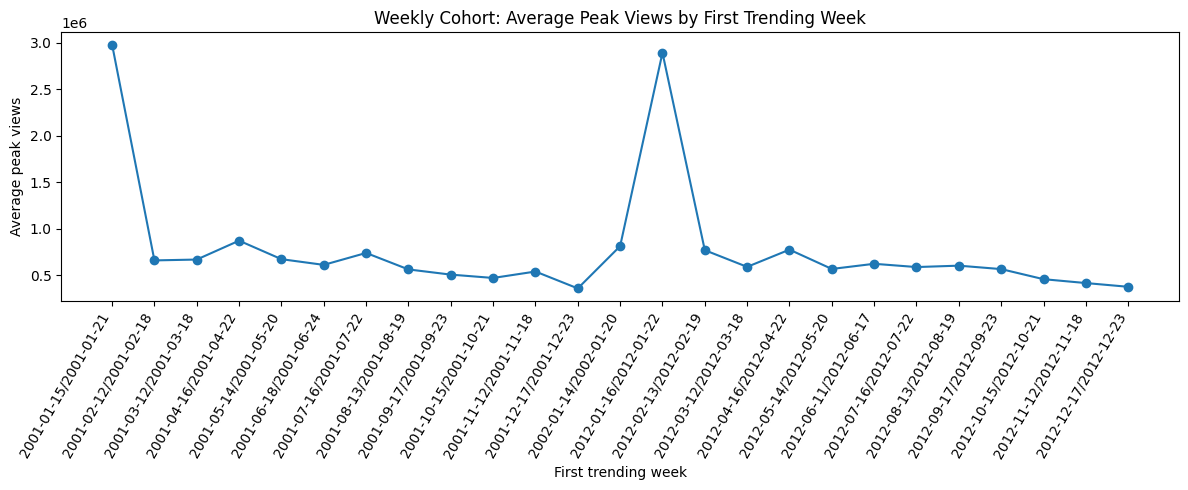

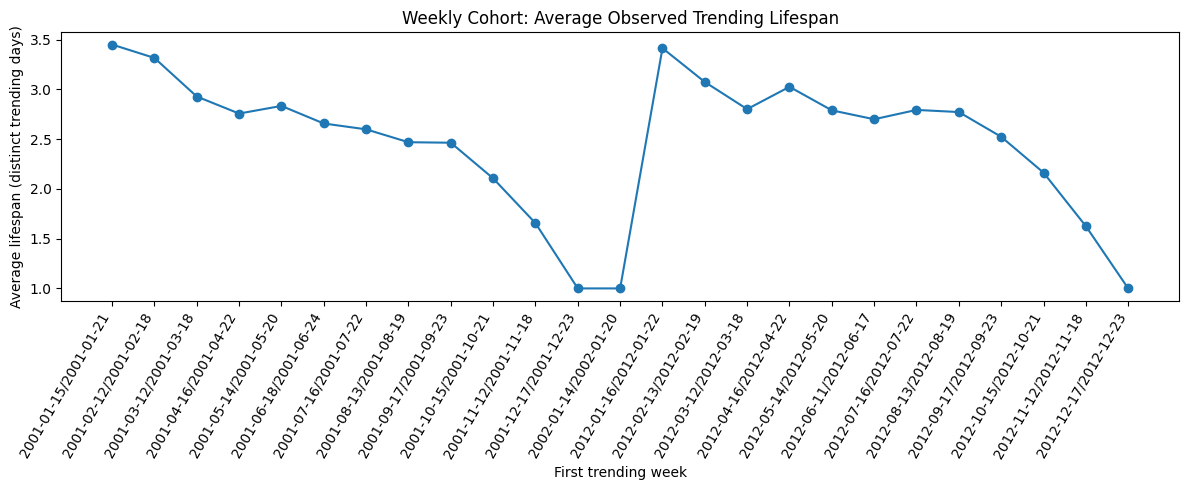

Largest weekly cohort: 2001-01-15/2001-01-21 (600 videos).
Interpretation: Cohorts with higher average peak views or lifespan may have different performance, but this is descriptive rather than causal. Weeks with few videos can have unstable averages, so always inspect video_count before comparing cohorts.


In [26]:
video_first["first_trending_week"] = video_first["first_trending_date"].dt.to_period("W").astype(str)
video_first["first_trending_month"] = video_first["first_trending_date"].dt.to_period("M").astype(str)

cohort_metrics = videos[["country", "video_id", "peak_views", "trending_days"]].merge(
    video_first[["country", "video_id", "first_trending_week", "first_trending_month", "lifespan_days"]],
    on=["country", "video_id"], how="left"
)
weekly_cohort = cohort_metrics.groupby("first_trending_week", as_index=False).agg(
    video_count=("video_id", "nunique"),
    average_peak_views=("peak_views", "mean"),
    average_lifespan_days=("lifespan_days", "mean")
)
display(weekly_cohort.head(10))

plt.figure(figsize=(12, 5))
plt.plot(weekly_cohort["first_trending_week"], weekly_cohort["average_peak_views"], marker="o")
plt.title("Weekly Cohort: Average Peak Views by First Trending Week")
plt.xlabel("First trending week")
plt.ylabel("Average peak views")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(weekly_cohort["first_trending_week"], weekly_cohort["average_lifespan_days"], marker="o")
plt.title("Weekly Cohort: Average Observed Trending Lifespan")
plt.xlabel("First trending week")
plt.ylabel("Average lifespan (distinct trending days)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

if not weekly_cohort.empty:
    biggest_cohort = weekly_cohort.loc[weekly_cohort["video_count"].idxmax()]
    print(
        f"Largest weekly cohort: {biggest_cohort['first_trending_week']} "
        f"({int(biggest_cohort['video_count']):,} videos)."
    )
print(
    "Interpretation: Cohorts with higher average peak views or lifespan may have different performance, but this is descriptive rather than causal. "
    "Weeks with few videos can have unstable averages, so always inspect video_count before comparing cohorts."
)

## 18. Content strategy briefing (5–8 sentences, generated from this run)

The paragraph below inserts actual numbers from the notebook run. Because the files were generated synthetically, treat it as a demonstration of evidence-based reporting, not a claim about real YouTube.

In [29]:
def safe_num(x, digits=0):
    return "N/A" if pd.isna(x) else f"{x:,.{digits}f}"

total_records = len(df)
total_unique = len(videos)
category_record_counts = df["category_name"].value_counts()
top_category_name = category_record_counts.index[0] if len(category_record_counts) else "Unknown"
top_category_records = int(category_record_counts.iloc[0]) if len(category_record_counts) else 0
country_avg_views = videos.groupby("country")["peak_views"].mean().sort_values(ascending=False)
best_country = country_avg_views.index[0] if len(country_avg_views) else "N/A"
best_country_avg = country_avg_views.iloc[0] if len(country_avg_views) else np.nan
ret_day2 = float(retention_summary.loc[retention_summary["day"] == 2, "percent_of_videos"].iloc[0]) if len(retention_summary) else np.nan
ret_day7 = float(retention_summary.loc[retention_summary["day"] == 7, "percent_of_videos"].iloc[0]) if len(retention_summary) else np.nan
avg_lifespan = video_first["lifespan_days"].mean() if len(video_first) else np.nan
top_corr = pairs[0] if pairs else None
funnel_drop_text = (
    f"The largest absolute funnel drop was {stage_names[largest_idx-1]} to {stage_names[largest_idx]} "
    f"({dropoffs[largest_idx-1]:,} videos)."
    if dropoffs else "The funnel drop-off could not be calculated."
)

briefing = (
    f"This synthetic TrendPulse dataset contains {total_records:,} trending records representing "
    f"{total_unique:,} unique country/video units across {', '.join(COUNTRIES)}. "
    f"{top_category_name} contributes the most trending records ({top_category_records:,}), although repeated daily appearances mean record counts are not the same as unique-video counts. "
    f"{best_country} has the highest average peak views by country ({safe_num(best_country_avg)}), so country-level differences deserve further investigation alongside sample sizes. "
    f"About {safe_num(ret_day2, 2)}% of observed videos remain trending on day 2 and {safe_num(ret_day7, 2)}% on day 7; these values describe observed persistence in this dataset. "
    f"The average observed trending lifespan is {safe_num(avg_lifespan, 2)} distinct days, and the funnel shows where the strongest numerical filtering occurs. "
    f"{funnel_drop_text} "
    f"Use categories with higher median peak views or longer retention as candidates for deeper review, but do not treat association as proof that category causes performance. "
    f"Important limitation: the data are synthetic and cover a fixed observation window, include only videos that trended, and may not represent real YouTube audiences or recommendation behavior."
)
print(briefing)

This synthetic TrendPulse dataset contains 14,600 trending records representing 5,575 unique country/video units across US, IN, GB. Entertainment contributes the most trending records (3,839), although repeated daily appearances mean record counts are not the same as unique-video counts. GB has the highest average peak views by country (1,484,577), so country-level differences deserve further investigation alongside sample sizes. About 59.07% of observed videos remain trending on day 2 and 6.26% on day 7; these values describe observed persistence in this dataset. The average observed trending lifespan is 2.62 distinct days, and the funnel shows where the strongest numerical filtering occurs. The largest absolute funnel drop was All videos that trended to Peak views above median (2,788 videos). Use categories with higher median peak views or longer retention as candidates for deeper review, but do not treat association as proof that category causes performance. Important limitation: th

## 19. Export useful result tables

These CSVs are optional outputs for documenting the analysis or adding selected results to the README. They are saved in the notebook's current working directory.

In [28]:
profile.to_csv("part3_data_profile.csv")
summary_table.to_csv("part3_distribution_summary.csv")
funnel_table.to_csv("part3_funnel_summary.csv", index=False)
retention_summary.to_csv("part3_retention_summary.csv", index=False)
weekly_cohort.to_csv("part3_weekly_cohort_summary.csv", index=False)
print("Saved: part3_data_profile.csv, part3_distribution_summary.csv, part3_funnel_summary.csv, part3_retention_summary.csv, part3_weekly_cohort_summary.csv")

Saved: part3_data_profile.csv, part3_distribution_summary.csv, part3_funnel_summary.csv, part3_retention_summary.csv, part3_weekly_cohort_summary.csv


## 20. Final checklist

Before committing this notebook to GitHub, confirm:
- [ ] All four CSV files are in `part3_visualization_eda/data/`.
- [ ] The notebook runs top-to-bottom without errors.
- [ ] The actual output tables and plots are visible after running.
- [ ] Every chart has a title and axis labels; relevant legends are present.
- [ ] Interpretations are reviewed against the actual outputs.
- [ ] The README explains how to install/run, the synthetic-data limitation, cleaning choices, key funnel/retention findings, cohort conclusion, and the 5–8 sentence briefing.
- [ ] Commit the completed notebook on `part3-visualization-eda`, then open a pull request and merge into `main` after checking the diff.